# Lab Week 2 – Basics of Machine Learning + Regression Models

This week's lab will provide an overview of Machine Learning Basics, followed by implementing Regression Models.  

You will be using Scikit-learn, an open-source machine learning library that supports supervised and unsupervised learning. It also provides various tools for model fitting, data preprocessing, model selection, model evaluation, and many other utilities.

You can start by activating the COMP3222 virtual environment that was introduced last week. The virtual environment should already have the required packages pre-installed.

In [11]:
#Let's start by importing some necessary packages

import numpy as np
import pandas as pd
import sklearn as sk

# Get the Data

Let's start by downloading some data.

**Note:** If you are using Google Colab, this script will not work. Don't execute the cell below. You need to download the housing dataset yourself: https://github.com/ageron/data/blob/main/housing/housing.csv, and then upload it to the Files of your notebook (There is an icon for that on the left-side menu bar).

In [12]:
import pandas as pd
from pathlib import Path

def load_housing_data():
    # Use a relative path to look inside the datasets folder in your current directory
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


After running the above, you should now have a folder "datasets" in the same folder where the lab's ipynb file is. Inside that, a "housing" folder, and inside that a housing.csv.

Further, we are using pandas, a library for data analysis and statistics that is very helpful for doing dataset exploration. Note that we used read_csv to load housing.csv into a DataFrame, an in-memory structure that is very easy to analyse.

You can find an introduction to Pandas here: https://pandas.pydata.org/pandas-docs/stable/user_guide/10min.html to familiarise with the concepts of Series and DataFrames and what you can do with them. You will notice numpy arrays from last week form the basis of Series and DataFrames, and that many of the operations you learned last week for arrays also apply to Series and DataFrames.

If you need to run some of the examples in the guide, create a cell below and have fun.

## Exploring the dataset

Now you have the dataset loaded in memory, it's time to interrogate it. You are asking it:

* What type of variables it has (*numerical* or *categorical*?). 
* How many data points useful for my problem?
* Are there missing values? If so, in what variable(s)? how many?
* Has any variable been transformed or manipulated before it got to you?    

This is where pandas adds value over pure numpy, offering a number of convenient methods to calculate descriptive statistics.  

Skim over the DataFrame methods for 
* underlying data https://pandas.pydata.org/docs/reference/frame.html#attributes-and-underlying-data, and
* descriptive stats: https://pandas.pydata.org/docs/reference/frame.html#computations-descriptive-stats

In [22]:
# Use DataFrame.head() and DataFrame.tail() to view the top and bottom rows of the frame, respectively. 
housing.head()
housing.tail()
# Hint: Replace DataFrame with the name of the datset, i.e. housing



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [6]:
# Print a concise summary of the dataset
print(housing.info())
# Hint: Use Dataframe.info()



<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.5 MB
None


In [23]:
# Variables of dtype object are usually categorical (except if there was an error loading the dataset) 
# List the different values of the categorical variable in 'housing' and count the occurrences
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [24]:
# From the concise summary, we can see that one variable appears to have some null values
# Let's take a closer look at that subset.
# Create a slice of the housing data frame with the rows that have the value of that variable equal to null.
# Hint: learn about the isna() method
# An indication you got it right is that the number of rows you get is consistent with the number of null values you can derive from the consie summary

null_bedrooms= housing[housing['total_bedrooms'].isna()]
null_bdrooms = housing.isna().sum
null_bedrooms

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
182,-118.27,34.04,13.0,1784.0,NaN,2158.0,682.0,1.7038,118100.0,<1H OCEAN
327,-117.65,34.04,15.0,3393.0,NaN,2039.0,611.0,3.9336,151000.0,INLAND
366,-122.50,37.75,44.0,1819.0,NaN,1137.0,354.0,3.4919,271800.0,NEAR OCEAN
477,-117.99,34.14,30.0,2346.0,NaN,1988.0,474.0,2.5625,153000.0,INLAND
495,-114.59,34.83,41.0,812.0,NaN,375.0,158.0,1.7083,48500.0,INLAND
...,...,...,...,...,...,...,...,...,...,...
19880,-118.23,33.94,36.0,1110.0,NaN,1417.0,302.0,2.3333,92100.0,<1H OCEAN
19952,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20088,-119.73,36.83,8.0,3602.0,NaN,1959.0,580.0,5.3478,138800.0,INLAND
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN


In [31]:
import numpy as np
# Let's imagine you want to be proactive and anticipate someone will ask you to replace those values with something meaningful.
# Create a new dataframe with the empty cells replaced by the value of the variables household multiplied by 1.5, rounded down  
# (that is, assume in those places each household has 1.5 bedrooms)  
# Hint: read about the methods fillna() and np.floor(). And remember to make a copy to get a new data frame instead of a view.

bedrooms_replaced = housing.copy()
bedrooms_replaced['total_bedrooms'] = bedrooms_replaced['total_bedrooms'].fillna(np.floor(bedrooms_replaced['households']*1.5))
print(bedrooms_replaced.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [33]:
# add a command below to generate descriptive statistics of the housing dataset (hint: see the links provided below)
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


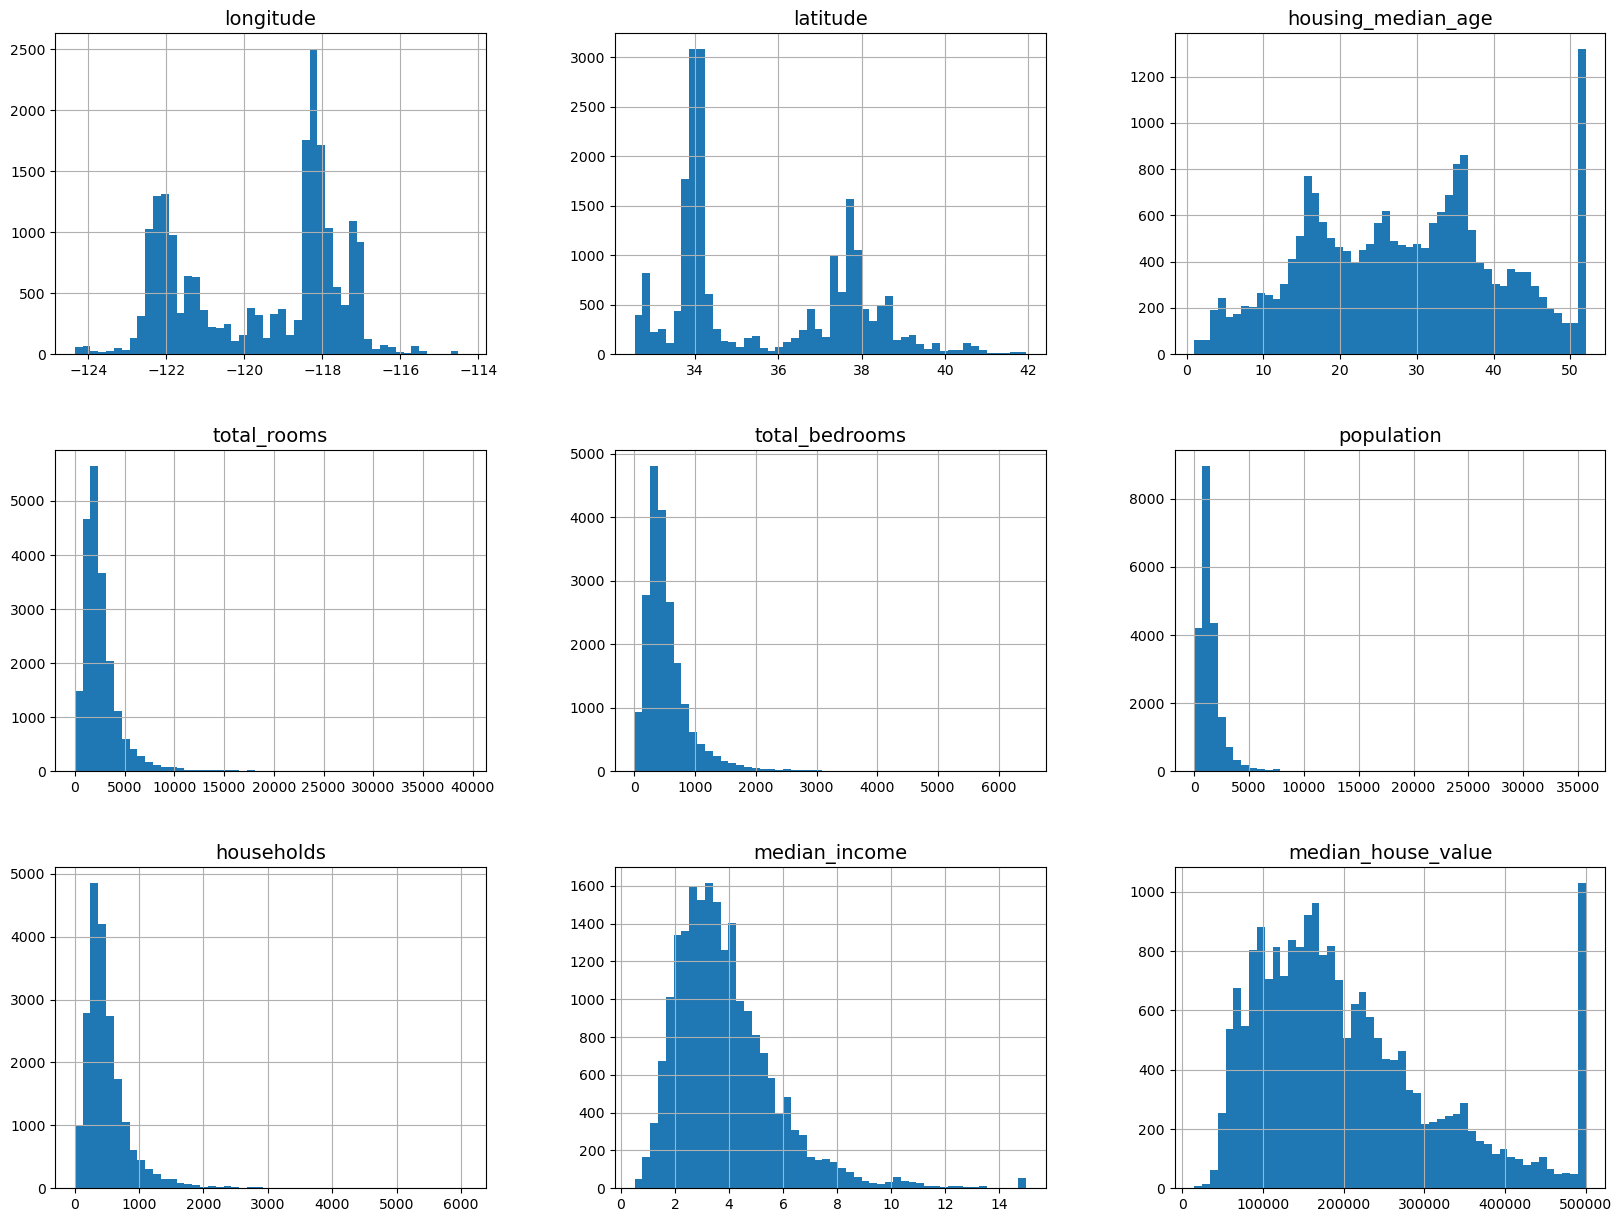

In [13]:
import matplotlib.pyplot as plt

#the next 5 lines define the default font sizes for all the figures
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# Another way to get more insight is by plotting histograms
# If you don't remember what a histogram is, go here https://chartio.com/learn/charts/histogram-complete-guide/
# Use the hist command for each variable, plot a histogram with 50 bins and a 20x15 size.
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html

housing.hist(bins=50, figsize=(20, 15))
plt.show()

# You may try experimenting with different number of bins to discover other patterns.

Now that we have the numbers and the figures, it's time to answer the questions we set up at the beginning

The type of variables it has (numerical or categorical?): 7 numerical, 2 geographical (also numerical), 1 categorical

How many data points useful for my problem? Initially all 20640, because all contain the target variable median_house_value:

Are there missing values? If so, in what variable(s)? how many?: 207 data points miss the total_bedrooms variable. If we believe total_bedrooms a useful feature for our model, something will have to be done with those data points.

Has any variable been transformed or manipulated before it got to you? :
This one is for you ;). Based on the stats and the histograms, what three variables have been manipulated before you? (hint, two of them have the same problem)

median income has very low values, it has been scaled by 10000 and capped at max. 15 (150000) and min 0.5 (5000)
housing_median_age has been capped at max 52 years
median_house_value has been capped at max 500000

## Dealing with categorical attributes 

The final data issue we look at in this session is to deal with the categorical attribute 'ocean_proximity'. Since most Machine Learning algorithms work on numerical vectors and matrices only, we need to transform the categorical attribute to a sensible numerical value that still represents its original meaning. 

**One-Hot Encoding** - Scikit-Learn provides a `OneHotEncoder` class to convert categorical values into one-hot vectors. The output is a sparse matrix with ones and zeros. Instead of one column with multiple categories, we will end up with multiple columns corresponding to the multiple categorical values the variable can take on. For each data point (represented as a row), you get a single $1$ where the data point belongs to that particular category, and the rest of them are $0$s.

In [15]:
# Code below - uncomment and run
from sklearn.preprocessing import OneHotEncoder

encoded_cat, categories = housing["ocean_proximity"].factorize() # retrieve the attribute encoded as numbers
encoded_cat_arr = OneHotEncoder().fit_transform(encoded_cat.reshape(-1,1)).toarray() # transform sparse matrix to NumPy array
enc_housing = housing.iloc[:,0:9].copy()
for i in range(0, len(categories)):
    enc_housing[categories[i]] = encoded_cat_arr[:,i]
    enc_housing.head()

After implementing the one-hot encoding, you can see that the categorical attribute 'ocean_proximity' transforms to 5 columns - 'NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN' and 'ISLAND'. These are all the possible categorical values for the variable 'ocean proximity'. Also note that for each row, you will have only one of these columns as $1$ and the rest as $0$.

# Linear Regression

We will now move on to implementing Regression Models. Refer to the 'Regression models' lecture slides to recap various concepts.

Instead of the above dataset, we will use a synthetic dataset to implement different variations of Regression easily. First, let us generate the dataset. We use the function, $y=4+3x+gaussian\_naoise$ to generate the data.

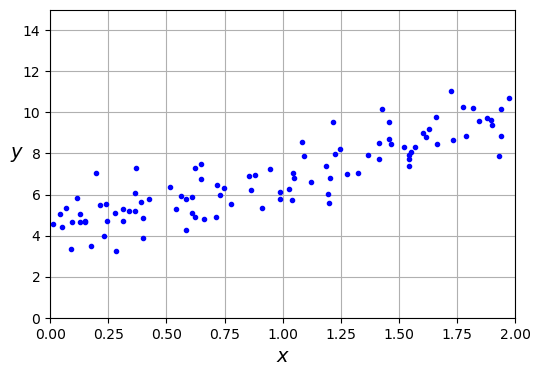

In [16]:
import numpy as np

np.random.seed(42)  # to make this code example reproducible
m = 100  # number of instances
X = 2 * np.random.rand(m, 1)  # column vector
y = 4 + 3 * X + np.random.randn(m, 1)  # column vector

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

Note from the lecture that if we have $n$ features, we will have $n$ weights and $1$ bias variable, i.e. $n+1$ parameters in the linear regression equation. To facilitate matrix multiplication, we add a dummy feature (a vector of ones) to the input.

In [17]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)  # add x0 = 1 to each instance

## Solving using the Normal Equation

Now we calculate $\hat\theta$ that minimizes the cost function. We can use the Normal equation, $\hat\theta = (X^TX)^{-1}X^Ty$ to solve for $\hat\theta$ directly. We use `inv()` function from the Numpy's `np.linalg` module to compute the inverse of a matrix and `dot()` method for matrix multiplication.

In [22]:
# insert code here
X_transpose =  X_b.T
X_transpose_X = np.dot(X_transpose, X_b)
inverse_matrix = np.linalg.inv(X_transpose_X)
theta = np.dot(np.dot(inverse_matrix, X_transpose), y)
print(theta)

[[4.21509616]
 [2.77011339]]


Since we added noise to the equation $y=4+3x$, it would be impossible to recover the parameters $θ_0 = 4$ and $θ_1 = 3$. Instead, we got $θ_0 = 4.215$ and $θ_1 = 2.770$, which is close enough. 

# Gradient Descent Optimization

Let's now implement Gradient Descent Optimisation to find $\hat\theta$. 

## Batch Gradient Descent

Batch gradient descent uses all the data at each iteration to calculate the gradient. 

**Recap**: 

* Start with a random initialisation of the parameter vector, theta
* At each step, calculate the gradient of the cost function, $gradients = 2/m*{X_b}^T(X\theta-y)$
* Update theta using the equation, $\theta = \theta - \eta*gradients$

In [26]:
# Edit the below code and run

eta = 0.1  # learning rate
n_epochs = 1000 # we are running this for 1000 iterations
m = len(X_b)  # number of instances

np.random.seed(42)
theta = np.random.randn(2, 1)  # randomly initialized model parameters

for epoch in range(n_epochs):
    # 1. Calculate gradients (2 * X^T * (X*theta - y) / m)
    gradients = 2 / m * np.dot(X_b.T, np.dot(X_b, theta) - y)
    
# take a descent step
theta = theta - eta * gradients

print("Theta", theta)

Theta [[1.78737583]
 [1.27927812]]


The trained model parameters:

In [ ]:
theta: 1.79

This is exactly what the Normal equation found. This demonstrates that Gradient Descent is successfully able to find the global minimum. You can experiment with different values of learning rate `eta`.

Below is a cool visualization of how the various learning rates change the outcome. We plot the first $20$ steps of the Gradient Descent using 3 different learning rates - $\eta = 0.02$, $\eta = 0.1$ and $\eta = 0.05$.

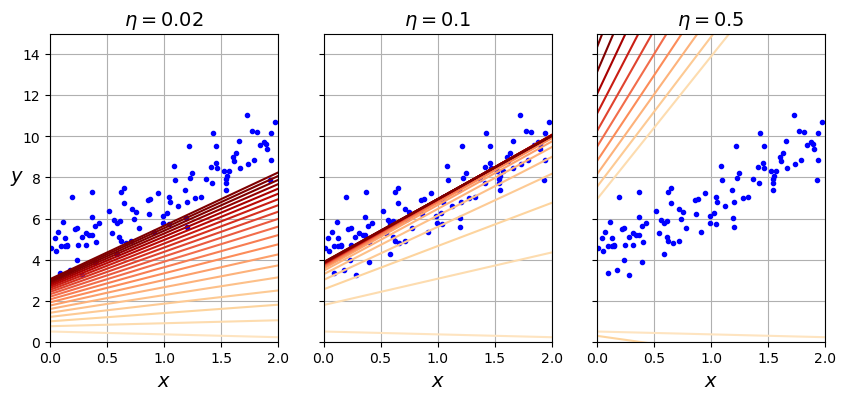

In [28]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- Generate synthetic data (Linear Regression example) ---
np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1)  # random x values between 0 and 2
y = 4 + 3 * X + np.random.randn(m, 1)  # y = 4 + 3x + noise

# Add bias term (column of ones) to X
X_b = np.c_[np.ones((m, 1)), X]

# X_new is a range of x values for smooth plotting
X_new = np.linspace(0, 2, 100).reshape(-1, 1)
X_new_b = np.c_[np.ones((100, 1)), X_new]

# --- Plotting function ---
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_epochs = 1000
    n_shown = 20
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

plt.figure(figsize=(10, 4))
plt.subplot(131)
plot_gradient_descent(theta, eta=0.02)
plt.ylabel("$y$", rotation=0)
plt.subplot(132)
theta_path_bgd = plot_gradient_descent(theta, eta=0.1)
plt.gca().axes.yaxis.set_ticklabels([])
plt.subplot(133)
plt.gca().axes.yaxis.set_ticklabels([])
plot_gradient_descent(theta, eta=0.5)
plt.show()

## Stochastic Gradient Descent

Stochastic Gradient Descent picks a random instance in the training set at each step to calculate the gradient. Below, we implement Stochastic Gradient Descent while also gradually reducing the learning rate. The steps start out large (which helps make quick progress and escape local minima), then get smaller and smaller, allowing the algorithm to settle at the global minimum. We use `learning schedule` to determine how the learning rate changes.

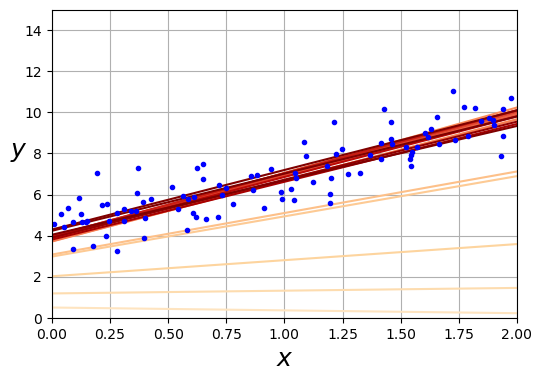

[[4.21076011]
 [2.74856079]]


In [30]:
theta_path_sgd = []  # extra code – we need to store the path of theta in the
                     #              parameter space to plot the next figure

n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

n_shown = 20  # extra code – just needed to generate the figure below
plt.figure(figsize=(6, 4))  # extra code – not needed, just formatting

for epoch in range(n_epochs):
    for iteration in range(m):

        # extra code – these 4 lines are used to generate the figure
        if epoch == 0 and iteration < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(iteration / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)

        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)

# extra code – formatting for the figure
plt.plot(X, y, "b.")
plt.xlabel("$x$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()
print (theta)

Now, let's see what the final theta looks like after Stochastic GD

In [ ]:
theta = 4.2

To perform Linear Regression using Stochastic GD with Scikit-Learn, you can use the `SGDRegressor` class.

In [ ]:
# Uncomment and run

from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())  # y.ravel() because fit() expects 1D targets

In [ ]:
sgd_reg.intercept_, sgd_reg.coef_

## Mini-batch gradient descent

Mini-batch GD computes the gradients at each step on small random sets of instances called mini-batches

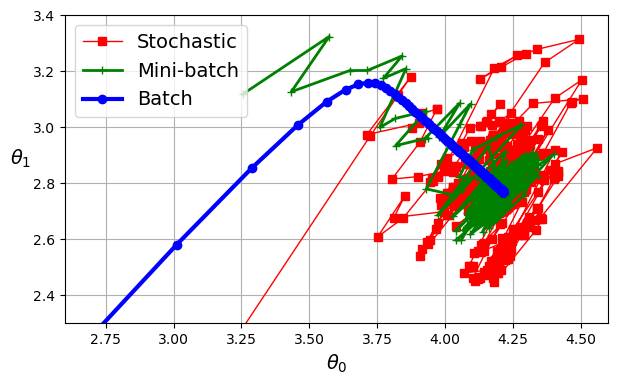

In [32]:
from math import ceil

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

t0, t1 = 200, 1000  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

theta_path_mgd = []
for epoch in range(n_epochs):
    shuffled_indices = np.random.permutation(m)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for iteration in range(0, n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b_shuffled[idx : idx + minibatch_size]
        yi = y_shuffled[idx : idx + minibatch_size]
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * n_batches_per_epoch + iteration)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

theta_path_bgd = np.array(theta_path_bgd)
theta_path_sgd = np.array(theta_path_sgd)
theta_path_mgd = np.array(theta_path_mgd)

plt.figure(figsize=(7, 4))
plt.plot(theta_path_sgd[:, 0], theta_path_sgd[:, 1], "r-s", linewidth=1,
         label="Stochastic")
plt.plot(theta_path_mgd[:, 0], theta_path_mgd[:, 1], "g-+", linewidth=2,
         label="Mini-batch")
plt.plot(theta_path_bgd[:, 0], theta_path_bgd[:, 1], "b-o", linewidth=3,
         label="Batch")
plt.legend(loc="upper left")
plt.xlabel(r"$\theta_0$")
plt.ylabel(r"$\theta_1$   ", rotation=0)
plt.axis([2.6, 4.6, 2.3, 3.4])
plt.grid()
plt.show()
